# QDiabetes-2018 (Model A) on Synthetic NABIDH EHR

**SYNTHETIC — NOT REAL PATIENT DATA**

This notebook:
1. Loads raw synthetic tables via the shared `qdiabetes_cohort` module
2. Builds the QDiabetes scoring cohort (same eligibility rules as validation)
3. Reports risk distributions, predictor coverage, and feasibility checks

**Not a medical device.** Townsend deprivation is unavailable in UAE synthetic data → defaults to `0`.

**Requirements:** `pip install pandas numpy matplotlib seaborn scikit-learn`

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from qdiabetes_cohort import (
    ETHNICITY_MAP,
    build_validation_cohort,
    load_tables,
)

sns.set_theme(style="whitegrid")
DATA_DIR = Path("output")

## 0. Coefficient-direction unit test (gate)

Runs the same 14 checks as `test_qdiabetes_directions.py` inline so the PASS/FAIL table appears in this notebook and the exported PDF.

In [2]:
from test_qdiabetes_directions import run_direction_checks, print_direction_table, score_one

_direction_results, _direction_pass = run_direction_checks()
print_direction_table(_direction_results, baseline=score_one())
assert _direction_pass, "Coefficient direction unit test FAILED — do not proceed with scoring"

QDiabetes-2018 Model A — coefficient direction unit test
Reference patient baseline risk: 3.6303%
----------------------------------------------------------------------------------------
Predictor                          Baseline    Variant      Delta   Expect Status
----------------------------------------------------------------------------------------
fhdm                                 3.6303     5.9366     2.3063       up   PASS
htn                                  3.6303     5.5771     1.9468       up   PASS
cvd                                  3.6303     4.3220     0.6917       up   PASS
ster                                 3.6303     4.7190     1.0887       up   PASS
apsy                                 3.6303     5.4169     1.7866       up   PASS
stat                                 3.6303     5.3577     1.7274       up   PASS
learn                                3.6303     4.1516     0.5213       up   PASS
psy                                  3.6303     4.6910     1.0606   

## 1. Build cohort & score (shared module)

Uses `qdiabetes_cohort.build_validation_cohort` — the same eligibility builder and `qdiabetes_2018a` scorer as the validation notebook.

In [3]:
tables = load_tables(DATA_DIR)
scoreable, eligible, funnel = build_validation_cohort(tables, return_eligible=True, return_funnel=True)
scoring = eligible  # full scoring cohort (BMI may be missing)

print("Cohort funnel (LOOKBACK_DAYS=365 index):")
print(f"  Total patients: {funnel['total_patients']:,}")
print(f"  Excluded — insufficient lookback: {funnel['excluded_insufficient_lookback']:,}")
print(f"  Excluded — T1D at/before index: {funnel['excluded_t1d_at_baseline']:,}")
print(f"  Excluded — prevalent T2D at/before index: {funnel['excluded_prevalent_t2d_at_baseline']:,}")
print(f"  Eligible scoring cohort: {funnel['eligible_cohort']:,}")
print(f"Scoring cohort (no DM/T1D at index): {len(scoring):,}")
print(
    f"Incident T2D after index — full scoring cohort: "
    f"{scoring['outcome_t2d'].sum():,} / {len(scoring):,} "
    f"({100 * scoring['outcome_t2d'].mean():.1f}%)"
)
print(
    f"Incident T2D after index — BMI-scoreable subset: "
    f"{scoreable['outcome_t2d'].sum():,} / {len(scoreable):,} "
    f"({100 * scoreable['outcome_t2d'].mean():.1f}%)"
)
print(f"Scoreable with BMI: {len(scoreable):,} ({100 * len(scoreable) / len(scoring):.1f}%)")

Cohort funnel (LOOKBACK_DAYS=365 index):
  Total patients: 100,000
  Excluded — insufficient lookback: 21,446
  Excluded — T1D at/before index: 421
  Excluded — prevalent T2D at/before index: 15,055
  Eligible scoring cohort: 63,078
Scoring cohort (no DM/T1D at index): 63,078
Incident T2D after index — full scoring cohort: 6,299 / 63,078 (10.0%)
Incident T2D after index — BMI-scoreable subset: 4,489 / 43,832 (10.2%)
Scoreable with BMI: 43,832 (69.5%)


## 2. NABIDH ethnicity → QDiabetes categories

| NABIDH category | QDiabetes `ethn` |
|-----------------|------------------|
| Indian | Indian |
| Pakistani | Pakistani |
| Bangladeshi | Bangladeshi |
| Other Asian, Filipino | OtherAsian |
| African | BlackAfrican |
| Western, Not recorded | WhiteNA |
| Emirati, Gulf Arab, Arab (non-Gulf) | **Other** (no UK category; documented mapping gap) |

In [4]:
scoring["ethn_qdiabetes"].value_counts()

ethn_qdiabetes
Indian          17719
Other           16298
OtherAsian       9549
Pakistani        7463
WhiteNA          5583
Bangladeshi      3883
BlackAfrican     2583
Name: count, dtype: int64

## 3. Predictor coverage (full scoring cohort, pre-index)

In [5]:
coverage = pd.DataFrame({
    "predictor": [
        "bmi", "smoking_status", "fhdm", "htn_treated", "cvd", "gdm", "pcos",
        "learn", "psy", "ster", "stat", "apsy",
    ],
    "pct_available_or_true": [
        100 * (~scoring["bmi_missing"]).mean(),
        100 * (~scoring["smoke_missing"]).mean(),
        100 * scoring["fhdm"].mean(),
        100 * scoring["htn"].mean(),
        100 * scoring["cvd"].mean(),
        100 * scoring["gdm"].mean(),
        100 * scoring["pcos"].mean(),
        100 * scoring["learn"].mean(),
        100 * scoring["psy"].mean(),
        100 * scoring["ster"].mean(),
        100 * scoring["stat"].mean(),
        100 * scoring["apsy"].mean(),
    ],
})
display(coverage.round(1))

,predictor,pct_available_or_true
0,bmi,69.5
1,smoking_status,62.7
2,fhdm,29.0
3,htn_treated,5.0
4,cvd,2.0
5,gdm,4.0
6,pcos,0.6
7,learn,0.5
8,psy,0.4
9,ster,0.4


## 4. Scoreable cohort risk summary

In [6]:
scoreable[["risk_10y_pct"]].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

,risk_10y_pct
count,43832.000000
mean,14.186559
std,16.164732
min,0.049519
10%,1.005684
25%,2.978594
50%,8.190441
75%,19.206093
90%,36.647494
max,99.991072


## 5. Risk distribution

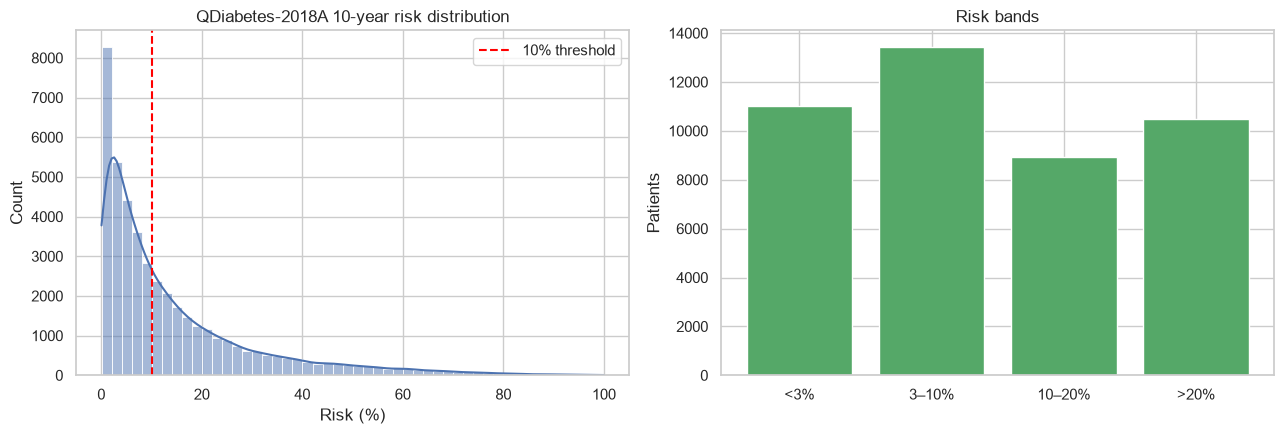

High risk (>10%): 19,399 patients (44.3%)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(scoreable["risk_10y_pct"], bins=50, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(10, ls="--", color="red", label="10% threshold")
axes[0].set_title("QDiabetes-2018A 10-year risk distribution")
axes[0].set_xlabel("Risk (%)")
axes[0].legend()

risk_band = pd.cut(
    scoreable["risk_10y_pct"],
    bins=[0, 3, 10, 20, 100],
    labels=["<3%", "3–10%", "10–20%", ">20%"],
    include_lowest=True,
)
band_counts = risk_band.value_counts().sort_index()
axes[1].bar(band_counts.index.astype(str), band_counts.values, color="#55A868")
axes[1].set_title("Risk bands")
axes[1].set_ylabel("Patients")
plt.tight_layout()
plt.show()

print(f"High risk (>10%): {(scoreable['risk_10y_pct'] > 10).sum():,} patients ({100*(scoreable['risk_10y_pct'] > 10).mean():.1f}%)")

## 6. Risk by demographics and key predictors

> **Note:** `test_qdiabetes_directions.py` confirms all QDiabetes-2018 Model A predictor directions are correct in the port. Where median risk if flag=True is *lower* than if False below (e.g. htn, cvd, ster), that reflects rare, confounded synthetic flag distributions — not a coefficient sign error.

/var/folders/bc/kx2zxl915sd4d8gswr4p_5v00000gn/T/ipykernel_36525/3636172148.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=scoreable, x="sex", y="risk_10y_pct", ax=axes[0, 0], palette="Set2")


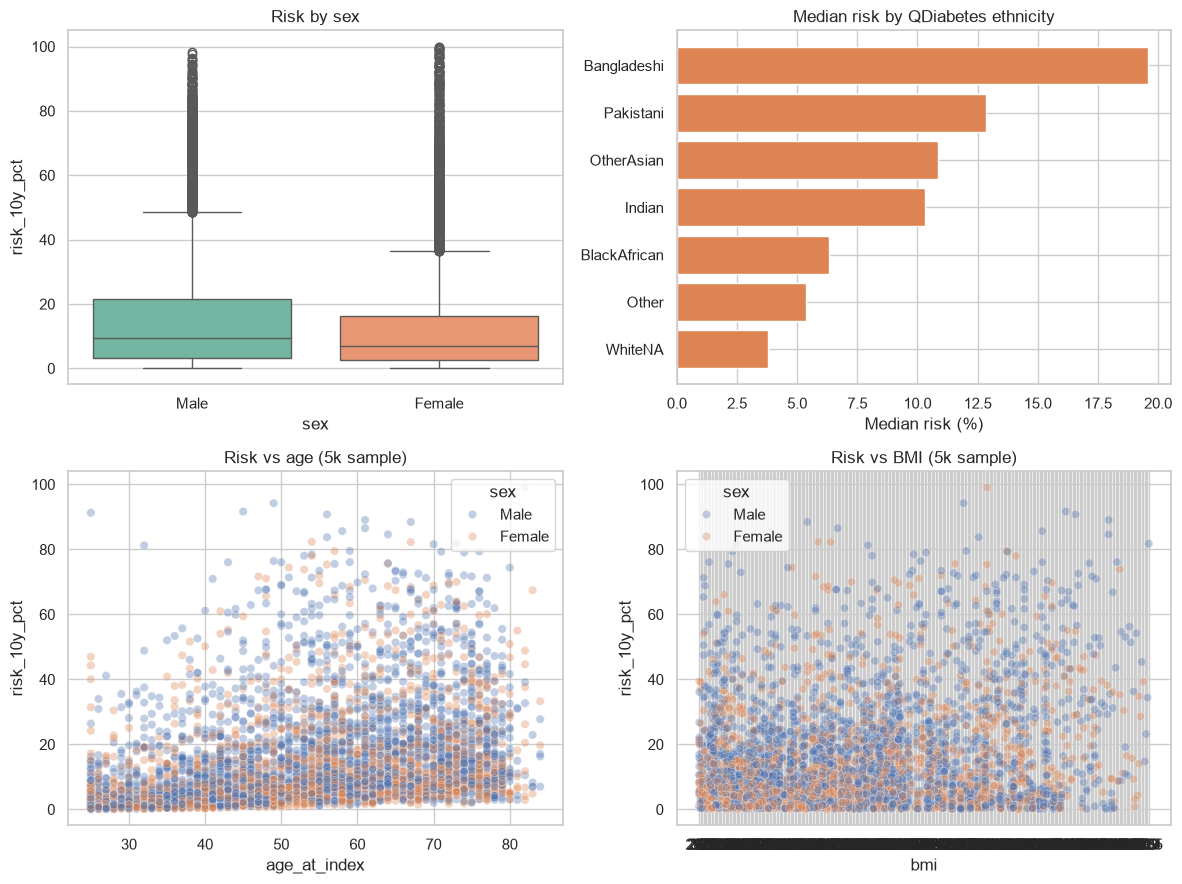

,predictor,median_risk_if_true,median_risk_if_false,prevalence_pct
0,fhdm,12.21,7.01,28.98
1,htn,11.23,8.07,5.03
2,cvd,9.30,8.18,2.02
3,gdm,25.29,7.94,3.34
4,stat,12.88,8.01,4.87
5,ster,10.72,8.18,0.45


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.boxplot(data=scoreable, x="sex", y="risk_10y_pct", ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Risk by sex")

eth_med = scoreable.groupby("ethn_qdiabetes")["risk_10y_pct"].median().sort_values(ascending=False).head(8)
axes[0, 1].barh(eth_med.index[::-1], eth_med.values[::-1], color="#DD8452")
axes[0, 1].set_title("Median risk by QDiabetes ethnicity")
axes[0, 1].set_xlabel("Median risk (%)")

sns.scatterplot(data=scoreable.sample(min(5000, len(scoreable)), random_state=42), x="age_at_index", y="risk_10y_pct", hue="sex", alpha=0.35, ax=axes[1, 0])
axes[1, 0].set_title("Risk vs age (5k sample)")

sns.scatterplot(data=scoreable.sample(min(5000, len(scoreable)), random_state=42), x="bmi", y="risk_10y_pct", hue="sex", alpha=0.35, ax=axes[1, 1])
axes[1, 1].set_title("Risk vs BMI (5k sample)")

plt.tight_layout()
plt.show()

pred_flags = ["fhdm", "htn", "cvd", "gdm", "stat", "ster"]
lift = []
for p in pred_flags:
    lift.append({
        "predictor": p,
        "median_risk_if_true": scoreable.loc[scoreable[p], "risk_10y_pct"].median(),
        "median_risk_if_false": scoreable.loc[~scoreable[p], "risk_10y_pct"].median(),
        "prevalence_pct": 100 * scoreable[p].mean(),
    })
display(pd.DataFrame(lift).round(2))

## 7. Feasibility check — risk vs incident diabetes after index

Descriptive check on synthetic data: patients who developed T2D **after** index should tend to have higher baseline QDiabetes scores among the BMI-scoreable subset.

,n,median,mean
outcome_t2d,,,
No incident T2D,39343,7.88,13.76
Incident T2D after index,4489,11.48,17.94


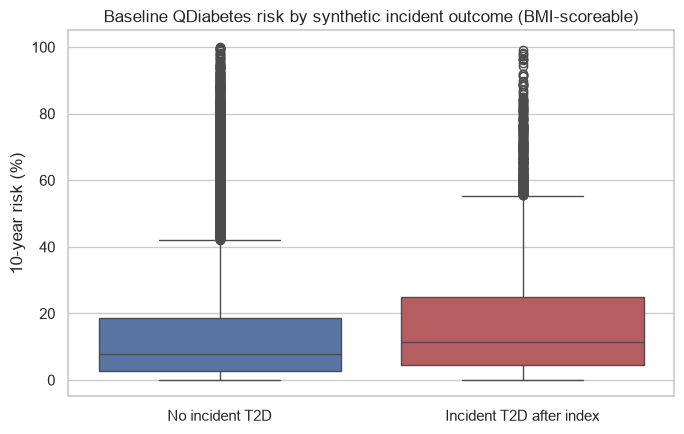

ROC AUC (risk vs incident outcome, n=43,832): 0.579


In [9]:
outcome_summary = scoreable.groupby("outcome_t2d")["risk_10y_pct"].agg(
    n="count", median="median", mean="mean"
).rename(index={False: "No incident T2D", True: "Incident T2D after index"})
display(outcome_summary.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(
    data=scoreable,
    x="outcome_t2d",
    y="risk_10y_pct",
    hue="outcome_t2d",
    ax=ax,
    palette=["#4C72B0", "#C44E52"],
    legend=False,
)
ax.set_xticks([0, 1])
ax.set_xticklabels(["No incident T2D", "Incident T2D after index"])
ax.set_title("Baseline QDiabetes risk by synthetic incident outcome (BMI-scoreable)")
ax.set_xlabel("")
ax.set_ylabel("10-year risk (%)")
plt.tight_layout()
plt.show()

auc = None
try:
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(scoreable["outcome_t2d"].astype(int), scoreable["risk_10y_pct"])
    print(f"ROC AUC (risk vs incident outcome, n={len(scoreable):,}): {auc:.3f}")
except ImportError:
    print("ROC AUC skipped — install scikit-learn")

## 8. Hypertension coding pattern (dx-only / med-only / both)

QDiabetes requires **treated** hypertension (dx + antihypertensive). Raw NABIDH data includes patients with diagnosis-only or medication-only patterns.

In [10]:
scoring_ids = set(scoring["patient_id"])
htn_patterns = pd.DataFrame({
    "pattern": [
        "dx_only",
        "med_only",
        "both (QDiabetes htn=True)",
        "neither",
    ],
    "patients": [
        scoring.loc[scoring["htn_dx_only"]].shape[0],
        scoring.loc[scoring["htn_med_only"]].shape[0],
        scoring.loc[scoring["htn"]].shape[0],
        scoring.loc[~scoring["htn"] & ~scoring["htn_dx_only"] & ~scoring["htn_med_only"]].shape[0],
    ],
})
htn_patterns["pct_scoring_cohort"] = 100 * htn_patterns["patients"] / len(scoring_ids)
display(htn_patterns.round(1))

,pattern,patients,pct_scoring_cohort
0,dx_only,4699,7.4
1,med_only,1733,2.7
2,both (QDiabetes htn=True),3160,5.0
3,neither,53486,84.8


## 9. Export scored cohort

In [11]:
export_path = Path("output/qdiabetes_scored_cohort.csv")
export_cols = [
    "patient_id", "index_date", "sex", "age_at_index", "ethn_qdiabetes", "bmi", "smoke",
    "fhdm", "htn", "cvd", "gdm", "pcos", "learn", "psy", "ster", "stat", "apsy",
    "risk_10y_pct", "outcome_t2d",
]
scoreable[export_cols].to_csv(export_path, index=False)
print(f"Wrote {len(scoreable):,} rows to {export_path}")

Wrote 43,832 rows to output/qdiabetes_scored_cohort.csv


## 10. Summary report

In [12]:
print("=" * 72)
print("QDIABETES-2018 MODEL A — SYNTHETIC NABIDH FEASIBILITY SUMMARY")
print("=" * 72)
print(f"Scoring cohort (no DM/T1D at index): {len(scoring):,}")
print(f"Scoreable with BMI: {len(scoreable):,} ({100*len(scoreable)/len(scoring):.1f}%)")
print(f"Median 10-year risk (scoreable): {scoreable['risk_10y_pct'].median():.2f}%")
print(f"High risk >10%: {(scoreable['risk_10y_pct']>10).sum():,} ({100*(scoreable['risk_10y_pct']>10).mean():.1f}%)")
print(
    f"Incident T2D after index (full cohort): {scoring['outcome_t2d'].sum():,} / {len(scoring):,} "
    f"({100*scoring['outcome_t2d'].mean():.1f}%)"
)
print(
    f"Incident T2D after index (BMI-scoreable): {scoreable['outcome_t2d'].sum():,} / {len(scoreable):,} "
    f"({100*scoreable['outcome_t2d'].mean():.1f}%)"
)
if auc is not None:
    print(f"ROC AUC vs incident outcome (BMI-scoreable): {auc:.3f}")
print()
print("Key feasibility notes:")
print("  • Townsend deprivation defaulted to 0 (UAE data)")
print("  • Emirati/Gulf Arab mapped to QDiabetes 'Other' — low ethnicity coefficient; may under-predict in high-risk Gulf populations")
print("  • Coefficient-direction unit test (test_qdiabetes_directions.py) passes — marginal predictor tables reflect synthetic confounding")
print("  • Treated HTN rule (dx + med) reduces HTN flag vs raw dx prevalence")
print("  • Missing BMI excludes patients from scoring")
print("=" * 72)

QDIABETES-2018 MODEL A — SYNTHETIC NABIDH FEASIBILITY SUMMARY
Scoring cohort (no DM/T1D at index): 63,078
Scoreable with BMI: 43,832 (69.5%)
Median 10-year risk (scoreable): 8.19%
High risk >10%: 19,399 (44.3%)
Incident T2D after index (full cohort): 6,299 / 63,078 (10.0%)
Incident T2D after index (BMI-scoreable): 4,489 / 43,832 (10.2%)
ROC AUC vs incident outcome (BMI-scoreable): 0.579

Key feasibility notes:
  • Townsend deprivation defaulted to 0 (UAE data)
  • Emirati/Gulf Arab mapped to QDiabetes 'Other' — low ethnicity coefficient; may under-predict in high-risk Gulf populations
  • Coefficient-direction unit test (test_qdiabetes_directions.py) passes — marginal predictor tables reflect synthetic confounding
  • Treated HTN rule (dx + med) reduces HTN flag vs raw dx prevalence
  • Missing BMI excludes patients from scoring
